Kaarina Mattika, CS87A, Section 1758
https://github.com/kmattika/cs82a-portfolio

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

In [2]:
df = pd.read_csv(r'C:\Users\kamat\Downloads\tips.csv')
display(df.head(10))
display(df.shape)
display(df.info())
display(df.describe())

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
5,25.29,4.71,Male,No,Sun,Dinner,4
6,8.77,2.00,Male,No,Sun,Dinner,2
7,26.88,3.12,Male,No,Sun,Dinner,4
8,15.04,1.96,Male,No,Sun,Dinner,2
9,14.78,3.23,Male,No,Sun,Dinner,2


(244, 7)

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    str    
 3   smoker      244 non-null    str    
 4   day         244 non-null    str    
 5   time        244 non-null    str    
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), str(4)
memory usage: 17.3 KB


None

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [3]:
X = df[['total_bill']]
y = df['tip']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (170, 1)
X_test: (74, 1)
y_train: (170,)
y_test: (74,)


We want to avoid letting the model test on data it's previously seen, because it will then remember previous answers and use that to complete testing rather than using the model itself. We can avoid overfitting by ensuring the model trains on fresh, never-before-seen data that removes the possibility of the model using retained answers - much like we would test a student on new material and not have them graded on re-examining their practice questions.

In [4]:
model = LinearRegression()
model.fit(X_train, y_train)
print(model.score(X_test, y_test))
print(model.coef_, model.intercept_)

0.4291782688312412
[0.10889371] 0.8769576391532699


Each dollar of bill added results in about $0.10 more of tip.

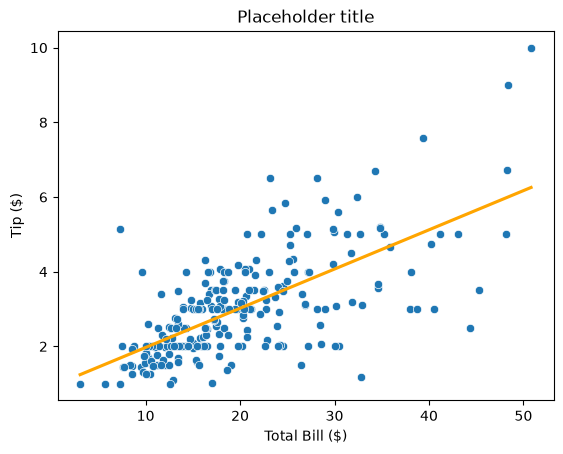

In [5]:
sns.scatterplot(
    data=df,
    x='total_bill',
    y='tip',
)

sns.regplot(
    data=df,
    x='total_bill',
    y='tip',
    scatter=False,
    color='orange',
    ci=None
)

plt.title('Placeholder title')
plt.xlabel('Total Bill ($)')
plt.ylabel('Tip ($)')
plt.show()

In [6]:
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (105, 4)
X_test: (45, 4)
y_train: (105,)
y_test: (45,)


In [7]:
knn = KNeighborsClassifier(n_neighbors=5)
tree = DecisionTreeClassifier(max_depth=3)
knn.fit(X_train, y_train)

test_accuracy = knn.score(X_test, y_test)
print('knn Test Accuracy:', test_accuracy)

knn Test Accuracy: 0.9777777777777777


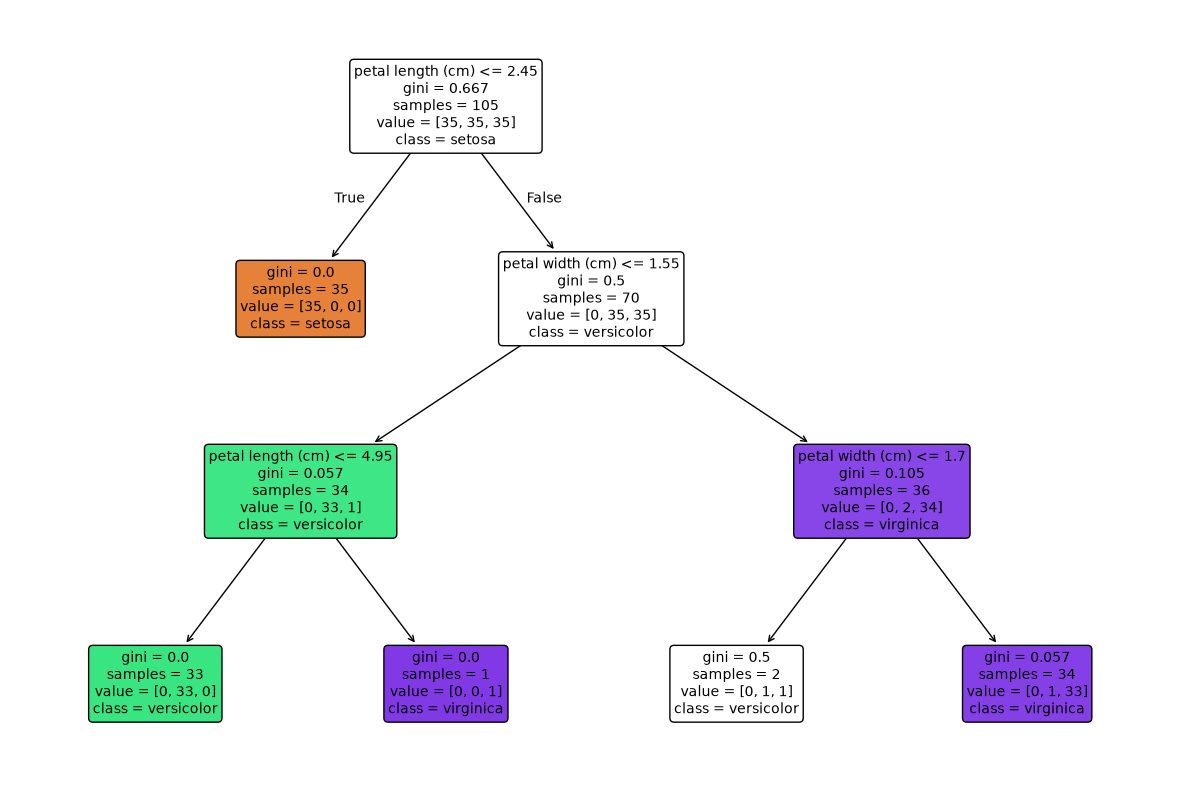

In [8]:
tree_3 = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_3.fit(X_train, y_train)
plt.figure(figsize=(15, 10))

plot_tree(
    tree_3,
    feature_names=X_train.columns,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=10,
)

plt.show()

In [9]:
tree_3_trainscore = tree_3.score(X_train, y_train)
tree_3_testscore = tree_3.score(X_test, y_test)

The first split sorts all setosa flowers into their own category, as all setosa flowers are less than or equal to 2.45 cm of petal length, with versicolor flowers generally having wider petals compared to virginica flowers. This trend is so strong that very few outliers fall outside of this dichotomy.

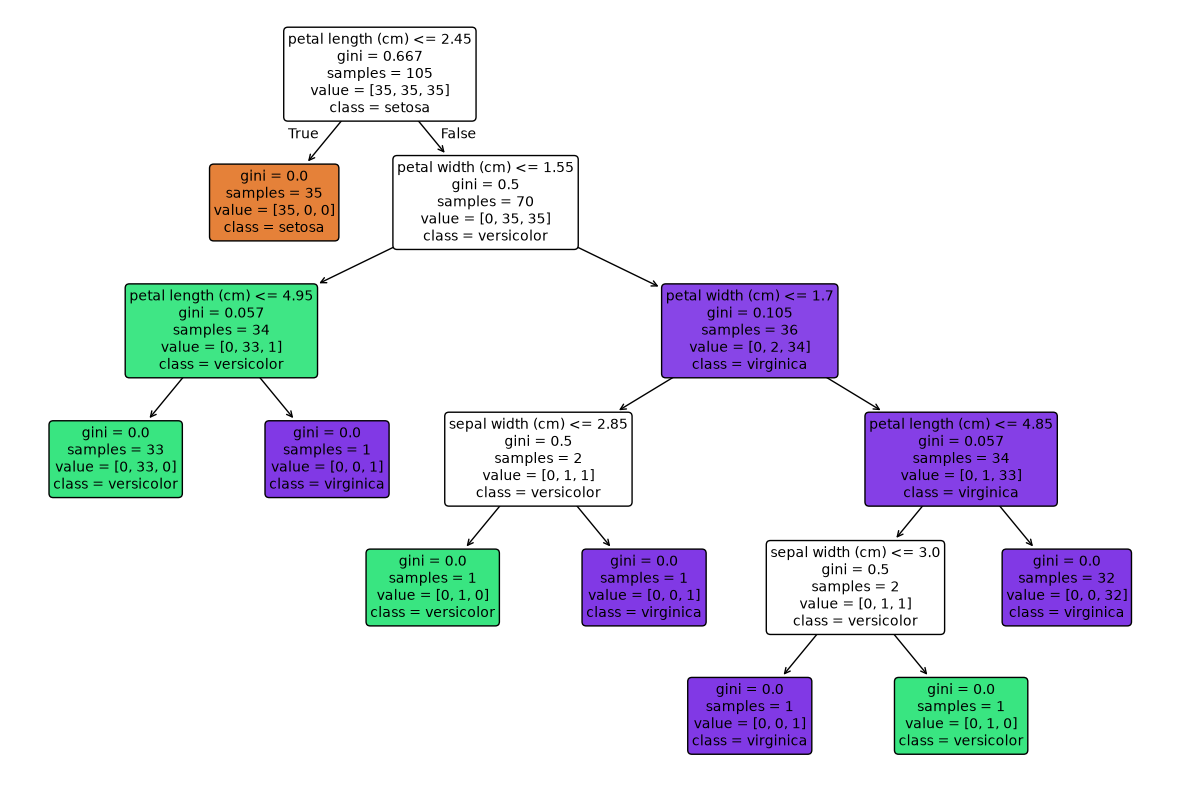

In [10]:
tree_full = DecisionTreeClassifier(random_state=42)
tree_full.fit(X_train, y_train)
plt.figure(figsize=(15, 10))

plot_tree(
    tree_full,
    feature_names=X_train.columns,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=10,
    max_depth=None,
)

plt.show()

In [11]:
tree_full_trainscore = tree_full.score(X_train, y_train)
tree_full_testscore = tree_full.score(X_test, y_test)

resultstable = pd.DataFrame({
    'Model': ['Depth of 3', 'No Max Depth'],
    'Train Score': [tree_3_trainscore, tree_full_trainscore],
    'Test Score': [tree_3_testscore, tree_full_testscore]
})

display(resultstable.round(3))

,Model,Train Score,Test Score
0,Depth of 3,0.981,0.978
1,No Max Depth,1.000,0.933


The tree with no max depth performs worse on the test than the training, which is a symptom of overfitting and tree oversizing; if a model is allowed to sort every entry into it's own individual category, it will correctly identify that every data point is unique without learning how to sort based on similar features. 

My created flower would have a petal length of 1.5 cm and a petal width of 1.0 cm, which would be sorted into the setosa branch due to it's noticably smaller petal length compared to versicolor or virginica flowers. 

In this assignment, we attempted to predict the change in tip size relative to dollars spent on a food order, as well as the classification of types of flowers based on the length and width of their petals. I feel somewhat confident using the regression model to predict tip sizes, but due to the discrete nature of using currency as our variables, I would give a caveat that we would likely need to round to the nearest five cents in order to maintain a high level of precision. In classifying our flowers, I feel significantly more confident using the tree with a maximum depth of three due to it's higher test score. Balancing accuracy and precision in this use case has been acheived by limiting the number of layers the model can sort to. In predicting future uses, this model may not be suitable for complex classification work where the samples belong to more than three categories and possessing more than three attributes; essentially, I would not rely on this model to sort samples into more complex categories - that may be a job better suited to a deeper layered tree. There would be a bias risk for using this type of model to evaluate humans, as well - if there was no age variable in our sample, our model may mistake children for adults and introduce significant instability into the training phase.